## Mini-proyecto de Machine Learning: predicción del rendimiento académico

## Paso 1. Definir la tarea

Problema: predecir si un estudiante aprobará la materia de matemáticas a partir de sus características personales, familiares y académicas.

Tipo de tarea: clasificación binaria supervisada con **Regresión Logística**.

Variable objetivo: `aprueba`, creada a partir de la nota final `G3`:
- `1` (clase positiva) = el estudiante aprueba (`G3 >= 10`).
- `0` = el estudiante no aprueba (`G3 < 10`).

Datos: dataset *Student Performance* del UCI Machine Learning Repository (395 estudiantes y 33 variables).

Utilidad y alcance: el modelo serviría como apoyo para identificar estudiantes que podrían necesitar acompañamiento académico. No debe usarse como decisión final sobre una persona.

In [13]:
import pandas as pd

df = pd.read_csv("data/student-mat.csv", sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [14]:
%pip install pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Paso 2. Recopilar y conocer los datos

- El dataset tiene **395 estudiantes y 33 variables**, sin que los valores sean nulos.
- Hay **16 variables numéricas** (edad, tiempo de estudio, fallos previos, ausencias, notas) y **17 categóricas** (colegio, sexo, zona, estudios y trabajo de los padres, apoyo familiar, etc.).
- La nota final `G3` va de 0 a 20 (media ≈ 10.4).
- Se observan notas finales en 0 y valores altos de ausencias (máximo 75), que pueden ser casos atípicos.
- Las variables categóricas deberán convertirse a números antes de entrenar el modelo.

In [20]:
df.info()
print("Nulos totales:", df.isna().sum().sum())
df[["age", "studytime", "failures", "absences", "G1", "G2", "G3"]].describe()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

,age,studytime,failures,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,0.334177,5.708861,10.908861,10.713924,10.415190
std,1.276043,0.839240,0.743651,8.003096,3.319195,3.761505,4.581443
min,15.000000,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,1.000000,0.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,2.000000,0.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,2.000000,0.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,3.000000,75.000000,19.000000,19.000000,20.000000


In [22]:
df["aprueba"] = (df["G3"] >= 10).astype(int)

print(df["aprueba"].value_counts())
print(df["aprueba"].value_counts(normalize=True).round(3))

aprueba
1    265
0    130
Name: count, dtype: int64
aprueba
1    0.671
0    0.329
Name: proportion, dtype: float64


## Paso 3. Representar la entrada de forma que el modelo pueda procesarla

- Variables y objetivo: `X` contiene las características de los estudiantes y `y` es la variable `aprueba`. Se eliminaron `G1`, `G2` y `G3`: `G3` porque de ella se construye el objetivo, y `G1` y `G2` porque son notas de periodos anteriores casi iguales a la final. Usarlas generaría fuga de información y el modelo parecería bueno sin serlo.

- Variables categóricas: columnas como `school`, `sex` o `address` son texto y el modelo solo entiende números. Se convirtieron con `pd.get_dummies`, que crea columnas de 0 y 1. Así `X` quedó con 39 columnas.

- Separación de datos: se dividió en 80 % para entrenar (316 estudiantes) y 20 % para probar (79 estudiantes). Se usó `stratify=y` para mantener la proporción de quienes aprueban (~67 %) en ambos conjuntos, y `random_state=42` para que el resultado sea reproducible.

- Estandarización: con `StandardScaler` las variables quedan en una escala comparable (media 0, desviación 1), lo que ayuda a la Regresión Logística. El escalador se ajusta solo con los datos de entrenamiento y luego se aplica a los de prueba, para que ningún dato de prueba influya en el entrenamiento.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Variables (X) y objetivo (y)
X = df.drop(columns=["G1", "G2", "G3", "aprueba"])
y = df["aprueba"]

# Convertir las columnas de texto a numéricas
X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Forma de X:", X.shape)

# Separar entrenamiento (80 %) y prueba (20 %), conservando la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("% aprueba en train:", round(y_train.mean(), 3), "| en test:", round(y_test.mean(), 3))

# Estandarizar: se ajusta solo con entrenamiento
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Forma de X: (395, 39)
Entrenamiento: (316, 39) | Prueba: (79, 39)
% aprueba en train: 0.671 | en test: 0.671


## Paso 4. Elegir un modelo

Se eligió la Regresión Logística, porque el problema es de clasificación binaria (aprueba / no aprueba), este es un modelo sencillo y sus coeficientes permiten ver qué variables pesan más en la predicción, lo cual es importante para explicar las decisiones. Como punto de comparación se usó un modelo de referencia(`DummyClassifier`) que siempre predice la clase más frecuente (aprueba); su accuracy esperado es ~0.67, y el modelo real debe superarlo.

## Paso 5. Entrenar el modelo

Entrenar significa que el modelo ajusta sus coeficientes usando únicamente los datos de entrenamiento (`X_train`, `y_train`; 316 estudiantes). Los datos de prueba no se usan en esta etapa.

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Modelo de referencia: siempre predice la clase más frecuente
modelo_ref = DummyClassifier(strategy="most_frequent")
modelo_ref.fit(X_train_s, y_train)

# Modelo principal: Regresión Logística
modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train_s, y_train)

print("Modelos entrenados con", X_train_s.shape[0], "estudiantes")

Modelos entrenados con 316 estudiantes


## Paso 6. Evaluar el desempeño

### 6.1 ¿Cómo se evaluó el modelo?

Evaluar significa comprobar qué tan bien funciona el modelo con datos que no vio durante el entrenamiento. Si se evaluara con los mismos estudiantes con los que aprendió, el resultado sería demasiado optimista, como un examen cuyas preguntas el estudiante ya conoce. Por eso se utilizó el conjunto de prueba: 79 estudiantes (el 20 % de los datos) reservados desde el Paso 3.

La clase positiva es "aprueba" (1) y la clase negativa es "no aprueba" (0). Esto importa porque las métricas se calculan respecto a la clase positiva.

Además de la Regresión Logística, se evaluó un modelo de referencia que siempre predice "aprueba". Sirve como punto de comparación mínimo: si el modelo real no lo supera, entonces no está aportando valor.

### 6.2 Métricas utilizadas y qué mide cada una

Las métricas se calculan a partir de cuatro conteos: VP (verdaderos positivos), VN (verdaderos negativos), FP (falsos positivos) y FN (falsos negativos).

| Métrica | Fórmula | Pregunta que responde |
|---|---|---|
| **Accuracy** | (VP + VN) / total | De todos los estudiantes, ¿a cuántos clasificó bien? |
| **Precisión** | VP / (VP + FP) | Cuando el modelo dice "aprueba", ¿qué tan seguido tiene razón? |
| **Recall** (sensibilidad) | VP / (VP + FN) | De los estudiantes que realmente aprueban, ¿a cuántos encuentra? |
| **F1-Score** | 2 · (precisión · recall) / (precisión + recall) | ¿Cómo está el balance entre precisión y recall? |

El accuracy por sí solo puede engañar cuando las clases están desbalanceadas (aquí el 67 % aprueba): un modelo que siempre diga "aprueba" ya acierta el 67 % sin aprender nada. Por eso también se miran la precisión, el recall y el F1, y se calculó el recall de la clase "no aprueba", que es la que más interesa para detectar estudiantes en riesgo.

In [30]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

resultados = []
for nombre, m in [("Referencia", modelo_ref), ("Regresión Logística", modelo)]:
    pred = m.predict(X_test_s)
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precisión": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

tabla = pd.DataFrame(resultados).round(3)
tabla

,Modelo,Accuracy,Precisión,Recall,F1
0,Referencia,0.671,0.671,1.000,0.803
1,Regresión Logística,0.633,0.707,0.774,0.739


### 6.3 Resultados e interpretación

Lectura de la tabla: la Regresión Logística obtiene un accuracy de 0.633, menor que el de la referencia (0.671), que predice "aprueba" para todos los estudiantes y acierta por el desbalance de las clases. La precisión del modelo (0.707) es un poco mayor que la de la referencia, mientras que el recall (0.774) y el F1 (0.739) son menores porque la referencia siempre predice "aprueba". Esto muestra que el accuracy por sí solo no basta para evaluar el modelo y que hay que revisar cómo se comporta con los estudiantes que no aprueban, lo que se analiza en la matriz de confusión.

Interpretación de cada métrica

- Accuracy = 0.633. De los 79 estudiantes de prueba, el modelo clasificó bien a 50 (63 %). Es menor que el de la referencia (0.671), que acierta solo porque la mayoría de los estudiantes aprueba.
- Precisión = 0.707. Cuando el modelo predice que un estudiante aprueba, acierta el 71 % de las veces; 3 de cada 10 predicciones de "aprueba" son errores.
- Recall = 0.774. De los 53 estudiantes que realmente aprobaron, el modelo identificó a 41 (77 %). La referencia tiene recall 1.000 porque predice "aprueba" para todos.
- F1-Score = 0.739. Combina precisión y recall. Es menor que el de la referencia (0.803) por la misma razón: la referencia tiene un recall perfecto.

[[ 9 17]
 [12 41]]
Recall de 'no aprueba': 0.346


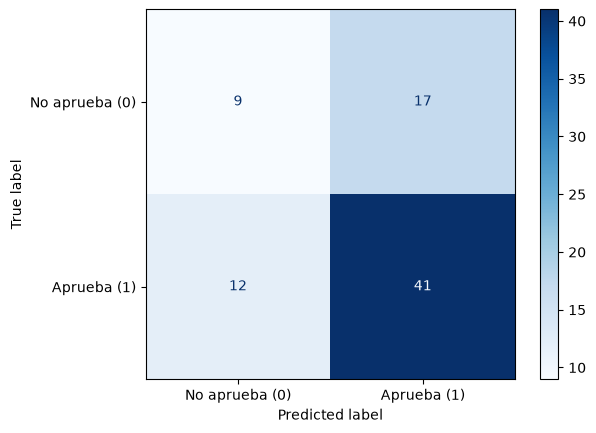

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score
import matplotlib.pyplot as plt

pred = modelo.predict(X_test_s)
print(confusion_matrix(y_test, pred))
print("Recall de 'no aprueba':", round(recall_score(y_test, pred, pos_label=0), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["No aprueba (0)", "Aprueba (1)"], cmap="Blues"
)
plt.show()

### 6.4 Matriz de confusión

La matriz de confusión compara lo que realmente pasó (filas) con lo que el modelo predijo (columnas). La diagonal (9 y 41) son los aciertos y los otros dos casilleros (17 y 12) son los errores.

| | Predice **no aprueba** | Predice **aprueba** |
|---|---|---|
| **Real: no aprueba** | 9 (VN) | 17 (FP) |
| **Real: aprueba** | 12 (FN) | 41 (VP) |

- Verdaderos positivos (VP = 41): estudiantes que aprobaron y que el modelo predijo que aprobarían.
- Verdaderos negativos (VN = 9): estudiantes que no aprobaron y que el modelo predijo que no aprobarían.
- Falsos positivos (FP = 17): el modelo predijo que aprobarían, pero no aprobaron. Es el error más delicado: son estudiantes en riesgo que el modelo no detectó y que podrían quedarse sin apoyo.
- Falsos negativos (FN = 12): el modelo predijo que no aprobarían, pero sí aprobaron. Es una "falsa alarma": se dedica apoyo a un estudiante que no lo necesitaba, un costo menor.

Recall de la clase "no aprueba" = 0.346. De los 26 estudiantes que realmente no aprobaron, el modelo solo detectó a 9 (9 / 26), es decir, deja pasar a casi dos de cada tres estudiantes en riesgo.

Interpretación: el modelo acierta sobre todo con quienes aprueban (41 de 53), pero casi no detecta a los que no aprueban. Esto es coherente con lo que se vio en la tabla de métricas: como la mayoría de los estudiantes aprueba, el modelo tiende a predecir "aprueba", y las variables del contexto aportan poca información para identificar a quienes están en riesgo.

### 6.5 Comparación con el modelo de referencia

El modelo de referencia no detecta a ningún estudiante que no apruebe (recall de "no aprueba" = 0), mientras que la Regresión Logística detecta a 9 de 26. En ese sentido aporta información, pero en accuracy y F1 global no supera a la referencia, por lo que su mejora es limitada.

### 6.6 Implicaciones

- Las variables del contexto tienen poco poder predictivo por sí solas: al excluir `G1` y `G2` (para evitar fuga de información), el modelo pierde la señal más fuerte.
- El modelo no es apto para tomar decisiones sobre un estudiante: deja pasar a casi dos de cada tres estudiantes que no aprueban. A lo sumo serviría como señal complementaria junto con el criterio de un docente.
- El resultado es incierto: con solo 79 estudiantes de prueba, un solo estudiante cambia el accuracy en más de un punto porcentual.
- Posibles mejoras: balancear las clases (se prueba más abajo), ajustar el umbral de decisión, recolectar más datos o probar otros modelos con validación cruzada.

In [33]:
modelo_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
modelo_bal.fit(X_train_s, y_train)
pred_bal = modelo_bal.predict(X_test_s)

print(confusion_matrix(y_test, pred_bal))

comparacion = []
for nombre, p in [("Referencia", modelo_ref.predict(X_test_s)),
                  ("Reg. Logística", pred),
                  ("Reg. Logística balanceada", pred_bal)]:
    comparacion.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, p),
        "Recall aprueba": recall_score(y_test, p),
        "Recall no aprueba": recall_score(y_test, p, pos_label=0),
        "Precisión no aprueba": precision_score(y_test, p, pos_label=0, zero_division=0),
    })

pd.DataFrame(comparacion).round(3)

[[12 14]
 [21 32]]


,Modelo,Accuracy,Recall aprueba,Recall no aprueba,Precisión no aprueba
0,Referencia,0.671,1.000,0.000,0.000
1,Reg. Logística,0.633,0.774,0.346,0.429
2,Reg. Logística balanceada,0.557,0.604,0.462,0.364


## Experimento: Regresión Logística con clases balanceadas

El modelo inicial detectaba pocos estudiantes que no aprueban (recall de "no aprueba" = 0.346). Se probó `class_weight="balanced"`, que da más peso a la clase minoritaria.

| Modelo | Accuracy | Recall aprueba | Recall no aprueba | Precisión no aprueba |
|---|---|---|---|---|
| Referencia | 0.671 | 1.000 | 0.000 | 0.000 |
| Reg. Logística | 0.633 | 0.774 | 0.346 | 0.429 |
| Reg. Logística balanceada | 0.557 | 0.604 | 0.462 | 0.364 |

Con el balanceo se detectan 12 de los 26 estudiantes que no aprueban (frente a 9), pero baja el accuracy y aumentan las falsas alarmas (21 estudiantes que sí aprueban son marcados como no aprobados). Para un uso de apoyo académico, donde una falsa alarma tiene poco costo y no detectar a un estudiante en riesgo es más grave, se eligió el modelo balanceado como modelo final. Con solo 79 estudiantes de prueba, la diferencia entre los modelos es pequeña y debe interpretarse con cautela.

In [34]:
import joblib, os

# Simulamos "estudiantes nuevos" con 5 estudiantes del conjunto de prueba
nuevos = X_test.head(5)
nuevos_s = scaler.transform(nuevos)

prob = modelo_bal.predict_proba(nuevos_s)[:, 1]
pred_nuevos = modelo_bal.predict(nuevos_s)

resultado = pd.DataFrame({
    "Prob. aprueba": prob.round(3),
    "Predicción": ["Aprueba" if p == 1 else "No aprueba" for p in pred_nuevos],
    "Real": ["Aprueba" if r == 1 else "No aprueba" for r in y_test.head(5)],
})

# Guardar el modelo y el escalador para usarlos después
os.makedirs("models", exist_ok=True)
joblib.dump(modelo_bal, "models/modelo_final.joblib")
joblib.dump(scaler, "models/scaler.joblib")

resultado

,Prob. aprueba,Predicción,Real
0,0.164,No aprueba,Aprueba
1,0.066,No aprueba,No aprueba
2,0.335,No aprueba,Aprueba
3,0.733,Aprueba,Aprueba
4,0.921,Aprueba,Aprueba


Paso 7. Usar el modelo entrenado con datos nuevos

Se aplicó el modelo final (Regresión Logística balanceada) a cinco estudiantes que no se usaron para entrenar. Para cada uno, el modelo entrega la probabilidad de que apruebe y una predicción: "Aprueba" si la probabilidad es mayor o igual a 0.5 y "No aprueba" en caso contrario.

| Estudiante | Prob. aprueba | Predicción | Real |
|---|---|---|---|
| 0 | 0.164 | No aprueba | Aprueba |
| 1 | 0.066 | No aprueba | No aprueba |
| 2 | 0.335 | No aprueba | Aprueba |
| 3 | 0.733 | Aprueba | Aprueba |
| 4 | 0.921 | Aprueba | Aprueba |

El modelo acertó en 3 de los 5 casos. En los otros 2 predijo "No aprueba" para estudiantes que sí aprobaron (falsas alarmas), lo cual es coherente con el balanceo de clases, que hace al modelo más propenso a marcar estudiantes en riesgo. Las predicciones muy seguras (probabilidades cercanas a 0 o a 1, como 0.066 y 0.921) fueron correctas, mientras que los casos con probabilidades intermedias son los más inciertos.

Los datos de un estudiante nuevo deben pasar por las mismas transformaciones del entrenamiento (columnas convertidas a números y estandarización con el mismo `scaler`). El modelo y el escalador se guardaron en la carpeta `models/` para reutilizarlos sin volver a entrenar.

Con solo 5 casos no se pueden sacar conclusiones sobre el desempeño general; es una demostración de uso. Dado el accuracy del modelo (0.557), sus predicciones no deben usarse para tomar decisiones sobre un estudiante, solo como una señal adicional para el docente.

In [35]:
pred_final = modelo_bal.predict(X_test_s)

grupos = {"sex_M": {0: "Mujeres", 1: "Hombres"},
          "address_U": {0: "Zona rural", 1: "Zona urbana"}}

filas = []
for col, nombres in grupos.items():
    for valor, nombre in nombres.items():
        mask = (X_test[col] == valor).values
        yt, yp = y_test[mask], pred_final[mask]
        filas.append({
            "Grupo": nombre,
            "n": int(mask.sum()),
            "% aprueba real": round(yt.mean(), 3),
            "% predicho aprueba": round(yp.mean(), 3),
            "Accuracy": round(accuracy_score(yt, yp), 3),
            "Recall no aprueba": round(recall_score(yt, yp, pos_label=0, zero_division=0), 3),
        })

pd.DataFrame(filas)

,Grupo,n,% aprueba real,% predicho aprueba,Accuracy,Recall no aprueba
0,Mujeres,47,0.638,0.511,0.404,0.353
1,Hombres,32,0.719,0.688,0.781,0.667
2,Zona rural,13,0.615,0.385,0.615,0.800
3,Zona urbana,66,0.682,0.621,0.545,0.381


## Análisis ético del modelo

### 1. Sesgos del dataset y del modelo

- **Representatividad:** los datos provienen de estudiantes de dos colegios de Portugal, recogidos hace casi veinte años. No representan a estudiantes de Colombia ni de otros contextos, por lo que el modelo no debería aplicarse fuera de ese entorno.
- **Tamaño:** solo hay 395 estudiantes (79 en la prueba). Con tan pocos datos, los resultados son inestables y los subgrupos son muy pequeños.
- **Variables sensibles:** el modelo usa información personal y familiar (sexo, edad, zona de vivienda, estudios y trabajo de los padres, situación de convivencia de los padres, consumo de alcohol, etc.). Algunas de estas variables pueden reflejar desigualdades sociales más que capacidad del estudiante.
- **Origen de la etiqueta:** "aprueba" depende de la nota final `G3`, que a su vez depende de criterios de evaluación de docentes y colegios. Si esa evaluación tiene sesgos, el modelo los hereda. Además, el corte `G3 >= 10` es una decisión del equipo.
- **Desbalance:** el 67 % de los estudiantes aprueba, lo que lleva al modelo a predecir "aprueba" con facilidad.

### 2. Equidad entre grupos

Se comparó el desempeño del modelo final por sexo y por zona de vivienda (conjunto de prueba):

| Grupo | n | % aprueba real | % predicho aprueba | Accuracy | Recall "no aprueba" |
|---|---|---|---|---|---|
| Mujeres | 47 | 0.638 | 0.511 | 0.404 | 0.353 |
| Hombres | 32 | 0.719 | 0.688 | 0.781 | 0.667 |
| Zona rural | 13 | 0.615 | 0.385 | 0.615 | 0.800 |
| Zona urbana | 66 | 0.682 | 0.621 | 0.545 | 0.381 |

- **Brecha por sexo:** el modelo acierta el 78 % de las veces con los hombres y solo el 40 % con las mujeres. También subestima a las mujeres: predice que aprueba el 51 % cuando en realidad aprueba el 64 %, mientras que en los hombres la predicción (69 %) es muy cercana a la realidad (72 %). En la práctica, las mujeres tienen más probabilidad de ser marcadas como "en riesgo" sin estarlo.
- **Detección de estudiantes en riesgo:** el recall de "no aprueba" es 0.353 en mujeres y 0.667 en hombres, es decir, el modelo detecta a más estudiantes en riesgo entre los hombres.
- **Zona de vivienda:** en la zona rural hay solo 13 estudiantes, por lo que sus resultados no son confiables. No se puede concluir si hay o no sesgo entre zonas.
- **Cautela:** con grupos tan pequeños parte de las diferencias puede deberse al azar, pero la brecha por sexo es lo bastante grande como para considerarla una señal de alerta que debería revisarse con más datos.

### 3. Privacidad y uso responsable de los datos

- El dataset contiene datos personales y familiares de estudiantes en su mayoría menores de edad. Aunque está anonimizado, en un uso real se necesitaría **consentimiento informado**, usar solo los datos necesarios (minimización) y guardarlos de forma segura.
- En Colombia, la **Ley 1581 de 2012** regula el tratamiento de datos personales y da una protección especial a los datos de niños, niñas y adolescentes.
- Los datos no deben usarse para fines distintos al apoyo académico (por ejemplo, para castigar, clasificar o excluir a estudiantes).

### 4. Impacto social

- **Posible beneficio:** identificar a tiempo estudiantes que podrían necesitar tutorías o acompañamiento.
- **Riesgos:** etiquetar a un estudiante como "en riesgo" puede generar estigma o bajar las expectativas de docentes y familia (profecía autocumplida). Si el modelo falla más con un grupo, ese grupo recibe más etiquetas injustas, como se observó con las mujeres. Además, con un accuracy de 0.557 el modelo se equivoca en casi la mitad de los casos.

### 5. Justicia y transparencia en la toma de decisiones

- Se eligió la **Regresión Logística** porque es interpretable: sus coeficientes permiten explicar qué variables empujan la predicción. Aun así, que un modelo sea explicable no significa que sea justo ni correcto.
- La decisión sobre un estudiante debe ser **humana**: el modelo solo puede ser una señal adicional para docentes y orientadores.
- El estudiante y su familia deberían saber que se usó un modelo, poder pedir una explicación y solicitar una revisión humana.
- Debería evaluarse periódicamente el desempeño por grupos y retirar el modelo si se comprueba que perjudica a alguno.

### 6. Conclusión ética

El modelo **no es apto para usarse en decisiones reales**: su desempeño general es bajo y, además, es claramente peor para las mujeres que para los hombres. Antes de cualquier uso práctico habría que recoger más datos del contexto local, revisar si variables como el sexo deberían excluirse del modelo, y volver a medir la equidad por grupos.